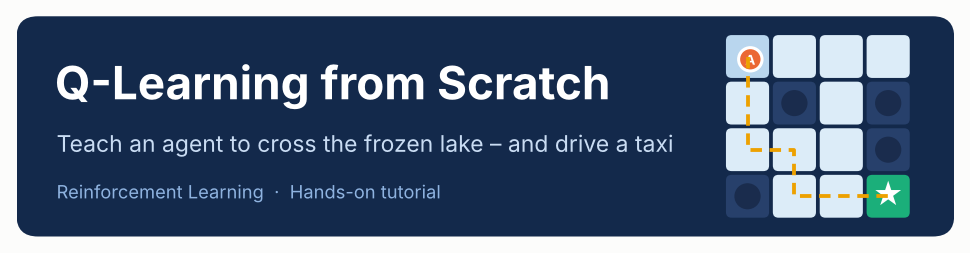

# Q-Learning from Scratch

In this notebook you will **build your first Reinforcement Learning (RL) agent yourself** – no RL library, just
Python and NumPy. The agent will learn to cross a frozen lake ⛄ without falling into a hole, and afterwards to
drive a taxi 🚕 that picks up and drops off passengers.

### 🏆 Learning goals

By the end you will be able to …

1. explain the **agent–environment loop** and the terms *state, action, reward, episode, policy*,
2. explain what a **Q-table** is and how the **Q-learning update rule** improves it,
3. explain the **exploration vs. exploitation** trade-off and implement an **ε-greedy policy**,
4. use **Gymnasium** environments and **train and evaluate** a Q-learning agent,
5. reason about the effect of **hyperparameters** (α, γ, ε-decay).

### 🧭 How to read this notebook

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ Blue boxes**

Background information and explanations.

</div>
<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Orange boxes — your tasks**

Replace every `...` in the code cell below the box with your own code. Hints are hidden behind **💡 Hint** – try without them first!

</div>
<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✅ Green boxes — checks**

After most tasks there is a *check cell*. Run it: it tells you if your code is correct.

</div>
<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Yellow boxes — think about it**

Short questions to discuss with your neighbour. We'll go through them together at the end.

</div>

**Jupyter basics:** a notebook consists of *cells*. Select a cell and press **Shift + Enter** (or the ▶ button) to run it.
Cells share their variables, so run them **from top to bottom**. If something behaves weirdly: *Runtime/Kernel → Restart* and run all cells again.

---
# Part 0 · Setup ⚙️

The next cell installs the packages we need. It works both in **Google Colab** and in a **local Jupyter** installation
(locally you can skip it if the packages are already installed).

- `gymnasium` – collection of RL environments (FrozenLake ⛄, Taxi 🚕, …)
- `numpy` – arrays, our Q-table will be a NumPy array
- `matplotlib`, `ipywidgets` – plots and interactive widgets

In [ ]:
#@title ⚙️ Install packages (≈ 30 s)
import sys
IN_COLAB = "google.colab" in sys.modules

%pip install -q "gymnasium[toy-text]>=1.0" ipywidgets matplotlib tqdm pillow

if IN_COLAB:  # makes interactive widgets work in Colab
    from google.colab import output
    output.enable_custom_widget_manager()

print("✅ Setup complete –", "running in Google Colab" if IN_COLAB else "running in local Jupyter")

Now we import the packages we need for the actual Q-learning code:

In [ ]:
import os
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")   # silences audio warnings of the renderer

import random                      # random numbers (for exploration)
import numpy as np                 # arrays → our Q-table
import gymnasium as gym            # the environments
from tqdm.auto import tqdm         # nice progress bars

The next cell contains **helper functions** for plots, widgets and automatic checks. It is collapsed – you do not need to
read it. **Just run it.**

In [ ]:
#@title 🔧 Helper functions & widgets — just run this cell (no need to read or change it)
# This cell only contains plotting / checking / widget code.
# Everything that matters for Q-Learning is written by YOU further below.
import io
import random
import threading
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
import ipywidgets as widgets
import gymnasium as gym
from IPython.display import display, HTML, clear_output, Image as IPyImage
from PIL import Image as PILImage

TAXI_ID = "Taxi-v4" if "Taxi-v4" in gym.registry else "Taxi-v3"   # newer gymnasium renamed Taxi
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", red="#e34948",
         violet="#4a3aa7", ink="#0b0b0b", ink2="#52514e", grid="#e4e3df", hole="#27406b")
ARROWS = {0: "←", 1: "↓", 2: "→", 3: "↑"}
FL_ACTIONS = {0: "LEFT", 1: "DOWN", 2: "RIGHT", 3: "UP"}
TAXI_ACTIONS = {0: "SOUTH", 1: "NORTH", 2: "EAST", 3: "WEST", 4: "PICKUP", 5: "DROPOFF"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": C["grid"], "grid.linewidth": 0.8, "axes.edgecolor": "#b5b4ae",
                     "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"],
                     "ytick.color": C["ink2"], "axes.titleweight": "bold", "figure.dpi": 100})


# ---------------------------------------------------------------- small utilities
def _box(msg, fg, bg):
    display(HTML(f"<div style='background:{bg};border-left:6px solid {fg};padding:8px 14px;"
                 f"border-radius:6px;color:#1b1b1b;margin:4px 0'>{msg}</div>"))


def _ok(msg):   _box("✅ " + msg, C["aqua"], "#e6f6ef")
def _fail(msg): _box("❌ " + msg, C["red"], "#fdeaea")


def frame_to_png(frame):
    buf = io.BytesIO()
    PILImage.fromarray(frame).save(buf, format="png")
    return buf.getvalue()


def fig_to_png(fig):
    """Render a matplotlib figure to PNG bytes (for widgets.Image) and close it."""
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=90, bbox_inches="tight")
    if plt.fignum_exists(getattr(fig, "number", -1)):
        plt.close(fig)
    return buf.getvalue()


def pngs_to_gif(pngs, ms_per_frame=800):
    """Combine PNG frames into one animated GIF (bytes). GIFs animate in every notebook frontend."""
    imgs = [PILImage.open(io.BytesIO(p)).convert("RGB") for p in pngs]
    buf = io.BytesIO()
    imgs[0].save(buf, format="gif", save_all=True, append_images=imgs[1:], duration=ms_per_frame, loop=0)
    return buf.getvalue()


def _player(n_frames, on_frame, interval=0.8, description="step"):
    """Play/pause + step buttons + slider. Playback runs in a Python thread
    (the built-in widgets.Play / jslink do not animate reliably in Google Colab)."""
    slider = widgets.IntSlider(min=0, max=max(n_frames - 1, 0), description=description,
                               layout=widgets.Layout(width="380px"))
    play = widgets.ToggleButton(value=False, description="▶ play", layout=widgets.Layout(width="95px"))
    prev = widgets.Button(description="◀", tooltip="previous", layout=widgets.Layout(width="42px"))
    nxt = widgets.Button(description="▶", tooltip="next", layout=widgets.Layout(width="42px"))
    state = {"thread": None}

    def loop():
        try:
            if slider.value >= slider.max:          # at the end → start again
                slider.value = 0
            while play.value and slider.value < slider.max:
                time.sleep(interval(slider.value) if callable(interval) else interval)
                if play.value:
                    slider.value += 1
        finally:
            play.value = False

    def toggled(ch):
        play.description = "⏸ pause" if ch["new"] else "▶ play"
        if ch["new"] and (state["thread"] is None or not state["thread"].is_alive()):
            state["thread"] = threading.Thread(target=loop, daemon=True)
            state["thread"].start()

    play.observe(toggled, names="value")
    prev.on_click(lambda _: setattr(slider, "value", max(slider.min, slider.value - 1)))
    nxt.on_click(lambda _: setattr(slider, "value", min(slider.max, slider.value + 1)))
    slider.observe(lambda ch: on_frame(ch["new"]), names="value")
    return widgets.HBox([play, prev, nxt, slider]), slider, play


def take_snapshot(episode, n_episodes):
    """Snapshot schedule for the Q-table history: dense at the start (where learning happens),
    sparse later (where the table has mostly converged)."""
    if episode == n_episodes - 1:
        return True
    if episode < 1000:
        return episode % 5 == 0
    if episode < 5000:
        return episode % 50 == 0
    return episode % max(1, n_episodes // 50) == 0


def moving_average(x, w):
    x = np.asarray(x, dtype=float)
    w = max(1, min(w, len(x)))
    return np.convolve(x, np.ones(w) / w, mode="valid")


def action_names(env):
    return TAXI_ACTIONS if env.action_space.n == 6 else FL_ACTIONS


# ---------------------------------------------------------------- plots
def plot_learning_curve(history, window=None, title="Training progress"):
    """Two stacked panels: smoothed reward per episode (top) and epsilon (bottom)."""
    r, e = history["rewards"], history["epsilons"]
    window = window or max(10, len(r) // 50)
    ma = moving_average(r, window)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 5), sharex=True,
                                 gridspec_kw=dict(height_ratios=[2, 1]))
    a1.plot(np.arange(window - 1, len(r)), ma, color=C["blue"], lw=2)
    a1.set_ylabel(f"reward\n(avg. of {window} episodes)")
    a1.set_title(title, loc="left")
    a2.plot(e, color=C["orange"], lw=2)
    a2.set_ylabel("epsilon ε")
    a2.set_xlabel("training episode")
    a2.set_ylim(0, 1.05)
    plt.tight_layout()
    plt.show()


def plot_q_table(Q, env, title=None, as_png=False):
    """FrozenLake only: greedy policy on the map (left) and the raw Q-table (right)."""
    desc = env.unwrapped.desc.astype(str)
    n = desc.shape[0]
    V = Q.max(axis=1).reshape(n, n)
    if as_png:   # object-oriented figure: safe to draw from the playback thread
        fig = Figure(figsize=(11, 4.8))
        a1, a2 = fig.subplots(1, 2, gridspec_kw=dict(width_ratios=[1, 1]))
    else:
        fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw=dict(width_ratios=[1, 1]))
    vmax = max(float(V.max()), 1e-9)
    a1.imshow(V, cmap="Blues", vmin=0, vmax=vmax * 1.25)
    small = n > 4
    for r in range(n):
        for c in range(n):
            s, t = r * n + c, desc[r, c]
            if t == "H":
                a1.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=C["hole"]))
            elif t == "G":
                a1.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color=C["aqua"]))
                a1.text(c, r, "★", ha="center", va="center", color="white", fontsize=14 if small else 26)
            elif np.all(Q[s] == 0):
                a1.text(c, r, "?", ha="center", va="center", color="#9a9994", fontsize=10 if small else 16)
            else:
                col = "white" if V[r, c] > 0.6 * vmax * 1.25 else C["ink"]
                a1.text(c, r - (0 if small else .12), ARROWS[int(np.argmax(Q[s]))], ha="center",
                        va="center", fontsize=12 if small else 24, color=col)
                if not small:
                    a1.text(c, r + .3, f"{V[r, c]:.2f}", ha="center", va="center", fontsize=9, color=col)
            if t == "S":
                a1.text(c - .42, r - .42, "S", ha="left", va="top", fontsize=8, color=C["ink2"])
    a1.set_xticks([]); a1.set_yticks([]); a1.grid(False)
    a1.set_title("Greedy policy  (arrow = argmax Q, number = max Q)", fontsize=10.5, loc="left")
    im = a2.imshow(Q, cmap="Blues", aspect="auto", vmin=0, vmax=vmax * 1.25)
    a2.grid(False)
    a2.set_xticks(range(4)); a2.set_xticklabels([f"{ARROWS[a]} {FL_ACTIONS[a]}" for a in range(4)], fontsize=9)
    a2.set_ylabel("state s")
    a2.set_title("Q-table  Q(s, a)", fontsize=10.5, loc="left")
    if not small:
        a2.set_yticks(range(16))
        for s in range(Q.shape[0]):
            for a in range(4):
                a2.text(a, s, f"{Q[s, a]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if Q[s, a] > 0.6 * vmax * 1.25 else C["ink"])
    if title:
        fig.suptitle(title, x=0.02, ha="left", fontweight="bold")
    fig.tight_layout()
    if as_png:
        return fig_to_png(fig)
    plt.show()


# ---------------------------------------------------------------- videos / replays
def rollout(env, Qtable, max_steps=99, seed=None):
    """Play one episode greedily. Returns frames, actions, rewards."""
    state, info = env.reset(seed=seed if seed is not None else random.randint(0, 500))
    frames, actions, rewards = [env.render()], [], []
    for _ in range(max_steps):
        action = int(np.argmax(Qtable[state]))
        state, reward, terminated, truncated, info = env.step(action)
        frames.append(env.render()); actions.append(action); rewards.append(reward)
        if terminated or truncated:
            break
    return frames, actions, rewards


def record_video(env, Qtable, out_path, max_steps=99, fps=1, seed=None):
    """Save a GIF of one greedy episode and display it."""
    frames, _, _ = rollout(env, Qtable, max_steps, seed)
    imgs = [PILImage.fromarray(f) for f in frames]
    imgs[0].save(out_path, save_all=True, append_images=imgs[1:], duration=int(1000 / fps), loop=0)
    return IPyImage(open(out_path, "rb").read())


def replay_widget(env, Qtable, max_steps=99):
    """Step through a greedy episode: ▶ play, ◀ ▶ single steps, slider, or as animated GIF."""
    img = widgets.Image(format="png", width="330")
    gif = widgets.Image(format="gif", width="330", layout=widgets.Layout(display="none"))
    info = widgets.HTML()
    names = action_names(env)
    data = {}

    def show(k):
        img.value = data["pngs"][k]
        if k == 0:
            info.value = "<b>start</b> – press ▶ play, use ◀ ▶ or drag the slider"
        else:
            info.value = (f"step {k}: action <b>{names[data['acts'][k-1]]}</b>, reward "
                          f"<b>{data['rews'][k-1]:+g}</b> &nbsp;|&nbsp; total so far: "
                          f"<b>{sum(data['rews'][:k]):+g}</b>")

    controls, slider, play = _player(1, show, interval=0.7)

    def new_episode(_=None):
        play.value = False
        frames, acts, rews = rollout(env, Qtable, max_steps)
        data.update(pngs=[frame_to_png(f) for f in frames], acts=acts, rews=rews)
        gif.layout.display = "none"
        slider.max = len(frames) - 1
        if slider.value == 0:
            show(0)
        else:
            slider.value = 0

    def as_gif(_):
        gif.value = pngs_to_gif(data["pngs"], 700)
        gif.layout.display = None

    btn_new = widgets.Button(description="new episode", icon="refresh")
    btn_new.on_click(new_episode)
    btn_gif = widgets.Button(description="as GIF", icon="film", tooltip="show this episode as animated GIF")
    btn_gif.on_click(as_gif)
    new_episode()
    return widgets.VBox([widgets.HBox([img, gif]), controls, widgets.HBox([btn_new, btn_gif]), info])


# ---------------------------------------------------------------- concept widgets
def play_frozenlake(map_name="4x4", is_slippery=False):
    """Play FrozenLake yourself with arrow buttons."""
    penv = gym.make("FrozenLake-v1", map_name=map_name, is_slippery=is_slippery, render_mode="rgb_array")
    st = {}
    img = widgets.Image(format="png", width="260")
    status = widgets.HTML()
    log = widgets.HTML()

    def refresh():
        img.value = frame_to_png(penv.render())
        msg = (f"state <b>{st['state']}</b> &nbsp;|&nbsp; steps <b>{st['steps']}</b> &nbsp;|&nbsp; "
               f"total reward <b>{st['reward']:g}</b>")
        if st["done"]:
            msg += (" &nbsp; 🏆 <b style='color:#1baf7a'>GOAL!</b>" if st["reward"] > 0
                    else " &nbsp; 💀 <b style='color:#e34948'>fell into a hole</b>") + " → press reset"
        status.value = msg
        log.value = "<div style='font-family:monospace;font-size:12px'>" + "<br>".join(st["log"][-6:]) + "</div>"

    def reset(_=None):
        s, _ = penv.reset()
        st.update(state=s, steps=0, reward=0.0, done=False, log=["reset → state 0"])
        refresh()

    def step(a):
        if st["done"]:
            return
        s2, r, te, tr, _ = penv.step(a)
        st["log"].append(f"state {st['state']:>2} --{FL_ACTIONS[a]:<5}--> state {s2:>2}  reward {r:g}")
        st.update(state=s2, steps=st["steps"] + 1, reward=st["reward"] + r, done=te or tr)
        refresh()

    def mk(a):
        b = widgets.Button(description=f"{ARROWS[a]} {a}", layout=widgets.Layout(width="70px"),
                           tooltip=f"action {a} = {FL_ACTIONS[a]}")
        b.on_click(lambda _: step(a))
        return b

    sp = lambda: widgets.Box(layout=widgets.Layout(width="74px"))
    pad = widgets.VBox([widgets.HBox([sp(), mk(3), sp()]), widgets.HBox([mk(0), mk(1), mk(2)])])
    rb = widgets.Button(description="reset", icon="refresh", button_style="warning")
    rb.on_click(reset)
    reset()
    return widgets.HBox([img, widgets.VBox([status, pad, rb, log], layout=widgets.Layout(margin="0 0 0 16px"))])


def update_rule_widget():
    """Explore one Q-learning update with sliders."""
    sl = dict(
        q=widgets.FloatSlider(value=0.5, min=-5, max=5, step=0.1, description="Q(s,a)"),
        r=widgets.FloatSlider(value=1.0, min=-10, max=20, step=0.5, description="reward r"),
        qn=widgets.FloatSlider(value=0.0, min=-5, max=5, step=0.1, description="max Q(s',·)"),
        alpha=widgets.FloatSlider(value=0.7, min=0, max=1, step=0.05, description="α (lr)"),
        gamma=widgets.FloatSlider(value=0.95, min=0, max=1, step=0.05, description="γ (gamma)"),
    )
    for w in sl.values():
        w.style = {"description_width": "90px"}
        w.layout = widgets.Layout(width="420px")
    out = widgets.HTML()

    def calc(*_):
        q, r, qn, a, g = (sl[k].value for k in ["q", "r", "qn", "alpha", "gamma"])
        target = r + g * qn
        err = target - q
        new = q + a * err
        out.value = f"""
        <div style='font-family:monospace;font-size:14px;line-height:1.9;color:#1b1b1b;
                    background:#f7f7f5;padding:10px 16px;border-radius:8px'>
        <span style='color:{C["aqua"]}'><b>TD target</b> = r + γ·maxQ(s') = {r:g} + {g:g}·{qn:g} = <b>{target:.3f}</b></span><br>
        <span style='color:{C["red"]}'><b>TD error</b> &nbsp;= target − Q(s,a) = {target:.3f} − {q:g} = <b>{err:+.3f}</b></span><br>
        <b>new Q(s,a)</b> = Q(s,a) + α·error = {q:g} + {a:g}·({err:+.3f}) = <b style='font-size:17px;color:{C["blue"]}'>{new:.3f}</b>
        </div>"""

    for w in sl.values():
        w.observe(calc, names="value")
    calc()
    return widgets.HBox([widgets.VBox(list(sl.values())), out])


def epsilon_decay_widget():
    """Explore the exponential epsilon schedule."""
    s = dict(
        max_epsilon=widgets.FloatSlider(value=1.0, min=0.1, max=1, step=0.05, description="max ε"),
        min_epsilon=widgets.FloatSlider(value=0.05, min=0, max=0.5, step=0.01, description="min ε"),
        decay_rate=widgets.FloatLogSlider(value=0.0005, base=10, min=-5, max=-1, step=0.1,
                                          description="decay rate", readout_format=".5f"),
        n_episodes=widgets.IntSlider(value=10000, min=500, max=50000, step=500, description="episodes"),
    )
    for w in s.values():
        w.style = {"description_width": "80px"}
        w.layout = widgets.Layout(width="380px")

    def draw(max_epsilon, min_epsilon, decay_rate, n_episodes):
        ep = np.arange(n_episodes)
        eps = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * ep)
        explore = np.mean(eps > 0.5)
        fig, ax = plt.subplots(figsize=(8, 3.2))
        ax.fill_between(ep, eps, color=C["orange"], alpha=.15, lw=0)
        ax.fill_between(ep, eps, 1, color=C["blue"], alpha=.10, lw=0)
        ax.plot(ep, eps, color=C["orange"], lw=2.5)
        ax.text(n_episodes * .98, 0.93, "exploit  (1 − ε)", ha="right", color=C["blue"], fontweight="bold")
        ax.text(n_episodes * .02, 0.05, "explore  (ε)", color=C["orange"], fontweight="bold")
        ax.set_ylim(0, 1.02); ax.set_xlim(0, n_episodes)
        ax.set_xlabel("training episode"); ax.set_ylabel("ε")
        ax.set_title(f"ε > 0.5 (mostly random actions) in {explore:.0%} of all episodes", loc="left", fontsize=11)
        plt.tight_layout()
        return fig_to_png(fig)

    img = widgets.Image(format="png", width="720")

    def update(*_):
        img.value = draw(**{k: w.value for k, w in s.items()})

    for w in s.values():
        w.observe(update, names="value")
    update()
    return widgets.VBox([widgets.HBox([widgets.VBox([s["max_epsilon"], s["min_epsilon"]]),
                                       widgets.VBox([s["decay_rate"], s["n_episodes"]])]), img])


def _select_snapshots(history, max_frames=45):
    """Pick the 'interesting' snapshots: every frame where the Q-table changed noticeably.
    Returns (episodes, durations_ms): big changes → slow frames, small changes → fast frames."""
    eps = sorted(history["snapshots"])
    S = [history["snapshots"][e] for e in eps]

    def greedy(thr):
        keep, last = [0], S[0]
        for i in range(1, len(eps) - 1):
            if np.max(np.abs(S[i] - last)) >= thr:
                keep.append(i); last = S[i]
        keep.append(len(eps) - 1)
        return keep

    lo, hi = 1e-4, 1.0                      # find the smallest threshold that gives ≤ max_frames frames
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if len(greedy(mid)) > max_frames else (lo, mid)
    keep = greedy(hi)
    # show the "nothing happens yet" phase as one frame just before the first change
    first_change = next((i for i in range(len(eps)) if np.any(S[i] != 0)), None)
    quiet = first_change - 1 if first_change else None
    if quiet is not None:
        keep = sorted(set(keep) | {quiet})
    # later phase: only a few fast frames (the table has mostly converged)
    late = {min(range(len(eps)), key=lambda i: abs(eps[i] - f * eps[-1])) for f in (0.1, 0.2, 0.35, 0.5, 0.75)}
    keep = sorted(set(keep) | {i for i in late if i > keep[-2]})
    durations, prev = [], S[keep[0]]
    for j, i in enumerate(keep):
        change = float(np.max(np.abs(S[i] - prev)))
        prev = S[i]
        if j == 0 or i == quiet:
            d = 1500                         # "nothing happens yet" (sparse reward)
        elif j == len(keep) - 1:
            d = 3000                         # hold the final table
        else:
            d = int(np.clip(300 + 3000 * change, 300, 1400))
        durations.append(d)
    return [eps[i] for i in keep], durations


def q_snapshot_widget(history, env):
    """Watch the Q-table during training (FrozenLake). Frames are chosen where the table
    changes – slow while a lot happens at the start, fast once it has converged."""
    eps, durations = _select_snapshots(history)
    goals = np.cumsum(np.asarray(history["rewards"]) > 0)      # successful episodes so far
    label = widgets.HTML()
    img = widgets.Image(format="png", width="900")
    gif = widgets.Image(format="gif", width="900", layout=widgets.Layout(display="none"))
    cache = {}

    def render(k):
        if k not in cache:
            ep = eps[k]
            title = (f"after episode {ep + 1}   (ε = {history['epsilons'][ep]:.2f})   ·   "
                     f"goal reached {int(goals[ep])}× so far")
            cache[k] = plot_q_table(history["snapshots"][ep], env, title=title, as_png=True)
        return cache[k]

    def show(k):
        ep, n_goal = eps[k], int(goals[eps[k]])
        img.value = render(k)
        hint = "" if n_goal else " &nbsp;→ <i>no reward seen yet, so every update writes 0 (sparse reward!)</i>"
        label.value = f"<b>episode {ep + 1}</b> &nbsp;|&nbsp; goal reached <b>{n_goal}×</b>{hint}"

    controls, slider, play = _player(len(eps), show, interval=lambda k: durations[k] / 1000,
                                     description="frame")

    def as_gif(_):
        play.value = False
        btn_gif.disabled = True
        for k in range(len(eps)):
            btn_gif.description = f"rendering {k + 1}/{len(eps)} …"
            render(k)
        gif.value = pngs_to_gif([cache[k] for k in range(len(eps))], durations)
        img.layout.display, gif.layout.display = "none", None
        btn_gif.description, btn_gif.disabled = "as GIF", False

    def back_to_slider(_):
        img.layout.display, gif.layout.display = None, "none"

    btn_gif = widgets.Button(description="as GIF", icon="film", tooltip="whole training as animated GIF")
    btn_gif.on_click(as_gif)
    slider.observe(back_to_slider, names="value")
    show(0)
    return widgets.VBox([controls, widgets.HBox([btn_gif, label]), img, gif])


ENV_CHOICES = {
    "FrozenLake 4x4": ("FrozenLake-v1", dict(map_name="4x4", is_slippery=False), 99),
    "FrozenLake 4x4 slippery": ("FrozenLake-v1", dict(map_name="4x4", is_slippery=True), 99),
    "FrozenLake 8x8": ("FrozenLake-v1", dict(map_name="8x8", is_slippery=False), 200),
    "FrozenLake 8x8 slippery": ("FrozenLake-v1", dict(map_name="8x8", is_slippery=True), 200),
    "Taxi": (TAXI_ID, {}, 99),
}


def hyperparameter_lab(train_fn, evaluate_fn, taxi_eval_seed, default_env="Taxi"):
    """Train + evaluate with chosen hyperparameters; keeps a table of all runs."""
    st = {"description_width": "110px"}
    lay = widgets.Layout(width="400px")
    w = dict(
        env=widgets.Dropdown(options=list(ENV_CHOICES), value=default_env, description="environment", style=st, layout=lay),
        # Dropdown instead of SelectionSlider: Colab sends float indices for SelectionSlider → TraitError
        n=widgets.Dropdown(options=[500, 1000, 2000, 5000, 10000, 25000, 50000], value=25000,
                           description="episodes", style=st, layout=lay),
        lr=widgets.FloatSlider(value=0.2, min=0.01, max=1, step=0.01, description="learning rate α", style=st, layout=lay),
        gamma=widgets.FloatSlider(value=0.5, min=0, max=0.999, step=0.005, readout_format=".3f",
                                  description="gamma γ", style=st, layout=lay),
        decay=widgets.FloatLogSlider(value=0.005, base=10, min=-5, max=-1, step=0.1, readout_format=".5f",
                                     description="decay rate", style=st, layout=lay),
        min_eps=widgets.FloatSlider(value=0.05, min=0, max=0.5, step=0.01, description="min ε", style=st, layout=lay),
    )
    btn = widgets.Button(description="Train & evaluate", button_style="success", icon="play",
                         layout=widgets.Layout(width="200px"))
    out, table = widgets.Output(), widgets.HTML()
    runs = []

    def run(_):
        btn.disabled = True
        with out:
            clear_output(wait=True)
            env_id, kw, max_steps = ENV_CHOICES[w["env"].value]
            lab_env = gym.make(env_id, render_mode="rgb_array", **kw)
            Q = np.zeros((lab_env.observation_space.n, lab_env.action_space.n))
            try:
                Q, hist = train_fn(env=lab_env, Qtable=Q, n_training_episodes=w["n"].value,
                                   learning_rate=w["lr"].value, gamma=w["gamma"].value, max_steps=max_steps,
                                   min_epsilon=w["min_eps"].value, max_epsilon=1.0, decay_rate=w["decay"].value)
                is_taxi = w["env"].value == "Taxi"
                n_eval = 100 if is_taxi else 1000
                mean, std = evaluate_fn(lab_env, max_steps, n_eval, Q, taxi_eval_seed if is_taxi else [])
                plot_learning_curve(hist, title=f"{w['env'].value}: training progress")
                if not is_taxi:
                    plot_q_table(Q, lab_env)
                goal = 7.0 if is_taxi else (1.0 if "slippery" not in w["env"].value else 0.7)
                (_ok if mean >= goal else _fail)(f"mean evaluation reward = <b>{mean:.2f} ± {std:.2f}</b>"
                                                 f" &nbsp; (target ≥ {goal})")
                runs.append((w["env"].value, w["n"].value, w["lr"].value, w["gamma"].value,
                             w["decay"].value, w["min_eps"].value, mean))
                rows = "".join(f"<tr><td>{i+1}</td><td>{r[0]}</td><td>{r[1]}</td><td>{r[2]:.2f}</td><td>{r[3]:.3f}</td>"
                               f"<td>{r[4]:.5f}</td><td>{r[5]:.2f}</td><td><b>{r[6]:.2f}</b></td></tr>"
                               for i, r in enumerate(runs))
                table.value = ("<b>Your runs</b><table style='border-collapse:collapse'><tr><th>#</th><th>env</th>"
                               "<th>episodes</th><th>α</th><th>γ</th><th>decay</th><th>min ε</th>"
                               "<th>mean reward</th></tr>" + rows + "</table>")
            except Exception as e:
                _fail(f"Training failed: <code>{e!r}</code> – are all your functions above complete?")
        btn.disabled = False

    btn.on_click(run)
    return widgets.VBox([widgets.HBox([widgets.VBox([w["env"], w["n"], w["lr"]]),
                                       widgets.VBox([w["gamma"], w["decay"], w["min_eps"]])]),
                         btn, table, out])


# ---------------------------------------------------------------- automatic checks
def _is_missing(x):
    return x is None or x is Ellipsis


def check_initialize_q_table(fn):
    try:
        Q = fn(16, 4)
    except Exception as e:
        return _fail(f"Your function raised an error: <code>{e!r}</code>")
    if _is_missing(Q):
        return _fail("The function returns nothing yet – did you replace the <code>...</code>?")
    Q = np.asarray(Q)
    if Q.shape != (16, 4):
        return _fail(f"Expected shape (16, 4) for 16 states and 4 actions, got {Q.shape}. "
                     "Hint: <code>np.zeros((rows, columns))</code> takes a tuple.")
    if not np.all(Q == 0):
        return _fail("All values should start at 0.")
    if np.asarray(fn(500, 6)).shape != (500, 6):
        return _fail("Works for (16, 4) but not for (500, 6) – don't hard-code the sizes!")
    _ok("Q-table initialisation looks correct.")


def check_greedy_policy(fn):
    Q = np.random.default_rng(0).random((16, 4))
    try:
        for s in range(16):
            a = fn(Q, s)
            if _is_missing(a):
                return _fail("The function returns nothing yet – did you replace the <code>...</code>?")
            if int(a) != int(np.argmax(Q[s])):
                return _fail(f"In state {s} the Q-values are {np.round(Q[s], 2)} → expected action "
                             f"{int(np.argmax(Q[s]))}, but got {a}. Use the row <code>Qtable[state]</code> only.")
    except Exception as e:
        return _fail(f"Your function raised an error: <code>{e!r}</code>")
    _ok("Greedy policy picks the action with the highest Q-value.")


def check_epsilon_greedy_policy(fn):
    Q = np.random.default_rng(1).random((16, 4))
    random.seed(0); np.random.seed(0)
    try:
        acts0 = [fn(Q, 3, 0.0) for _ in range(200)]
        if any(_is_missing(a) for a in acts0):
            return _fail("The function returns nothing yet – did you replace all <code>...</code>?")
        acts0 = [int(a) for a in acts0]
        best = int(np.argmax(Q[3]))
        if any(a != best for a in acts0):
            return _fail("With ε = 0 the agent must <b>always exploit</b> (choose argmax). "
                         "Is the comparison with epsilon the right way round?")
        acts1 = [int(fn(Q, 3, 1.0)) for _ in range(4000)]
        if not all(0 <= a < 4 for a in acts1):
            return _fail("Random actions must be valid action indices 0 … n_actions−1.")
        counts = np.bincount(acts1, minlength=4) / len(acts1)
        if counts.min() < 0.18:
            return _fail(f"With ε = 1 every action should be chosen about equally often, got {np.round(counts, 2)}.")
        greedy_share = np.mean([int(fn(Q, 3, 0.5)) == best for _ in range(4000)])
        if not 0.55 < greedy_share < 0.70:
            return _fail(f"With ε = 0.5 the best action should be chosen ≈ 62 % of the time "
                         f"(50 % exploit + 50 % · ¼ random), got {greedy_share:.0%}.")
    except Exception as e:
        return _fail(f"Your function raised an error: <code>{e!r}</code>")
    _ok("ε-greedy policy behaves correctly for ε = 0, 0.5 and 1.")


def check_train(fn):
    random.seed(0); np.random.seed(0)
    tenv = gym.make("FrozenLake-v1", map_name="4x4", is_slippery=False)
    tenv.reset(seed=0)
    try:
        out = fn(env=tenv, Qtable=np.zeros((16, 4)), n_training_episodes=1500, learning_rate=0.7, gamma=0.95,
                 max_steps=99, min_epsilon=0.05, max_epsilon=1.0, decay_rate=0.005)
        Q, history = out
        Q = np.asarray(Q)
    except Exception as e:
        return _fail(f"Training raised an error: <code>{e!r}</code> – check the lines with <code>...</code>.")
    if np.all(Q == 0):
        return _fail("The Q-table is still all zeros – is the update line writing into <code>Qtable[state][action]</code>?")
    if Q.max() > 1.0001:
        return _fail(f"Q-values larger than 1 (max {Q.max():.2f}) are impossible here – the only reward is +1. "
                     "Check the update formula (brackets!).")
    if abs(Q[14, 2] - 1.0) > 0.05:
        return _fail(f"Q(14, RIGHT) should be ≈ 1.0 (one step to the goal), got {Q[14, 2]:.3f}. "
                     "Check the TD target r + γ·max<sub>a'</sub> Q(s', a') in your update line.")
    if abs(Q[10, 1] - 0.95) > 0.05:
        return _fail(f"Q(10, DOWN) should be ≈ γ·1 = 0.95, got {Q[10, 1]:.3f}. "
                     "Is <code>np.max</code> taken over the <b>new</b> state's row? Do you update <code>state</code>?")
    if len(history["rewards"]) != 1500:
        return _fail("The history should contain one reward per episode – did you change the logging code?")
    _ok("Training loop works – Q-values match the theory (Q(14,→) ≈ 1, Q(10,↓) ≈ γ = 0.95).")


print(f"✅ Helpers loaded  (gymnasium {gym.__version__}, ipywidgets {widgets.__version__}, Taxi env id: {TAXI_ID})")

---
# Part 1 · The big picture 🧠

## 1.1 The agent–environment loop

In Reinforcement Learning an **agent** learns by **trial and error**. It does not get told what the correct action is –
it only gets a **reward** signal after acting.


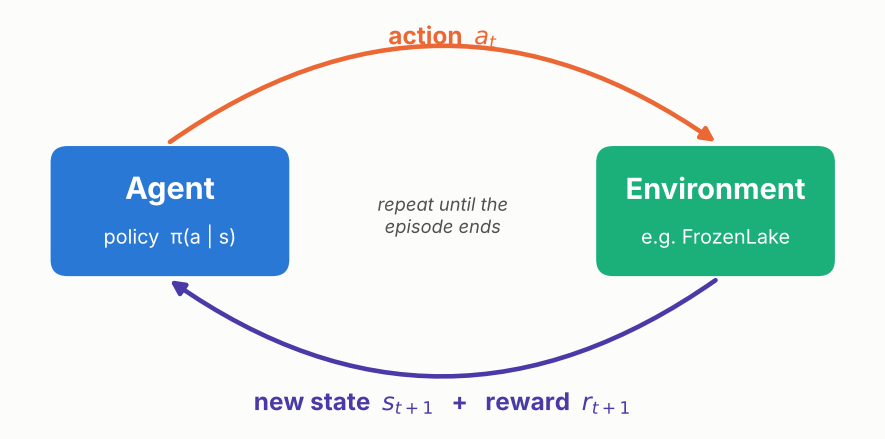

| Term | Meaning | FrozenLake example |
|:--|:--|:--|
| **state** $s$ | what the agent currently observes | the tile the agent stands on (0 … 15) |
| **action** $a$ | what the agent can do | LEFT, DOWN, RIGHT, UP |
| **reward** $r$ | feedback number after each action | +1 when reaching the goal, else 0 |
| **episode** | one run from the start until the end | start → goal *or* start → hole |
| **policy** $\pi$ | the agent's strategy: which action in which state? | “in state 14 go RIGHT” |

**Goal of the agent:** find a policy that collects as much (discounted) reward as possible over an episode.

## 1.2 The Q-table: the agent's memory

Q-learning learns a so-called **action-value function** $Q(s, a)$:

> $Q(s,a)$ = *“How much reward can I expect in the future if I take action $a$ in state $s$ — and act well afterwards?”*

Because FrozenLake and Taxi have only a few states and actions, we can store all these values in a simple **table**:
one row per state, one column per action.


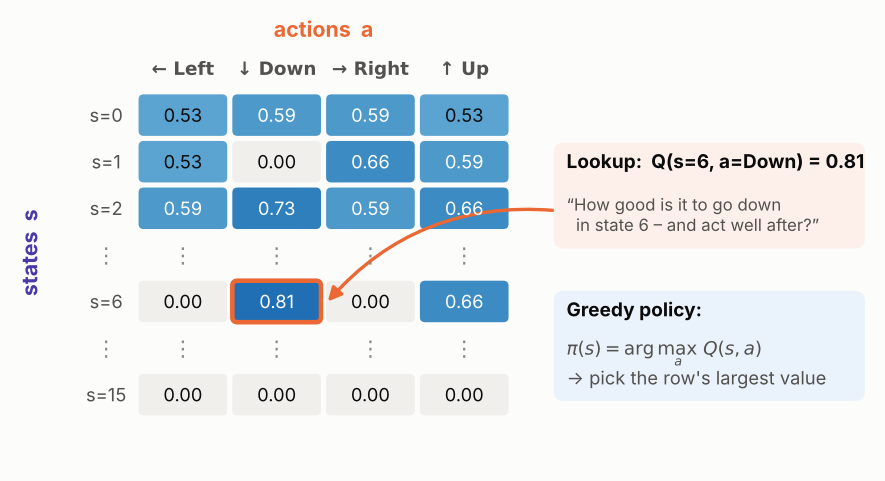

Once the table is good, acting is easy: in every state simply choose the action with the **largest Q-value**
(this is the **greedy policy**). Before training we know nothing, so the table starts with **all zeros**.

## 1.3 Learning: the Q-learning update rule

After every single step the agent has experienced a tiny piece of information: *“I was in state $s$, did $a$,
got reward $r$ and landed in $s'$.”* It uses this to **nudge** its old estimate $Q(s,a)$ a little bit
towards what it just experienced:


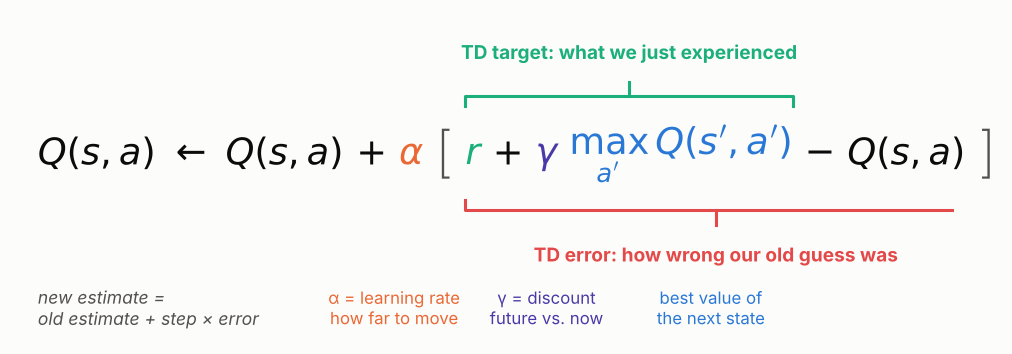

- The **TD target** $r + \gamma \max_{a'} Q(s',a')$ is a better guess: real reward now + (discounted) best value from the next state on.
- The **TD error** measures how wrong the old estimate was.
- The **learning rate** $\alpha \in [0,1]$ decides how big the nudge is; the **discount factor** $\gamma \in [0,1]$ how much future rewards count.

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎛️ Widget: play with the update rule**

Move the sliders and watch how one single update changes $Q(s,a)$.

</div>

In [ ]:
#@title 🎛️ Widget: update rule — run this cell
display(update_rule_widget())

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q1 & Q2)**

**Q1.** What happens to the learning if $\alpha = 0$? And if $\alpha = 1$?

**Q2.** In FrozenLake the only reward is +1 at the goal. What would the agent learn with $\gamma = 0$?

</div>

## 1.4 Exploration vs. exploitation: the ε-greedy policy

If the agent always picked the action that currently *looks* best, it would never discover better paths
(and at the beginning, with an all-zero table, everything looks equally bad!). So during training the agent sometimes
acts **randomly** on purpose:


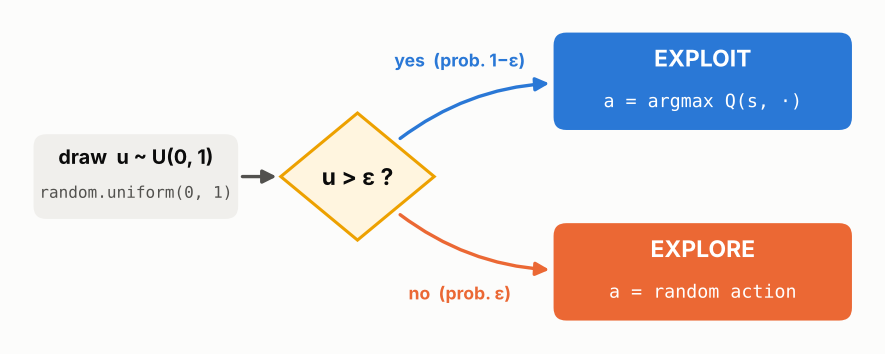

- With probability $\varepsilon$: **explore** – take a random action.
- With probability $1-\varepsilon$: **exploit** – take the greedy action $\arg\max_a Q(s,a)$.

At the start we know nothing ⇒ explore a lot ($\varepsilon \approx 1$). Later we trust our table ⇒ explore less. We therefore
let ε **decay exponentially** with the episode number:

$$\varepsilon(\text{episode}) = \varepsilon_{\min} + (\varepsilon_{\max} - \varepsilon_{\min}) \cdot e^{-\text{decay\_rate} \,\cdot\, \text{episode}}$$

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎛️ Widget: the ε schedule**

How does the `decay_rate` change how long the agent explores?

</div>

In [ ]:
#@title 🎛️ Widget: ε schedule — run this cell
display(epsilon_decay_widget())

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q3)**

**Q3.** Why don't we simply use ε = 0 (always greedy) right from the start? *Tip: what does `np.argmax([0, 0, 0, 0])` return?*

</div>

## 1.5 The complete algorithm

Putting everything together gives the Q-learning algorithm. The ✏️ labels show which task you will implement where.

<div style="background:#f7f7f5; border-radius:8px; padding:12px 20px; font-family:monospace; color:#1b1b1b; line-height:1.7">
<b>Initialise</b> Q(s, a) = 0 for all s, a &nbsp; <span style="color:#eb6834">← ✏️ Task 2</span><br>
<b>for</b> episode = 1 … N:<br>
&nbsp;&nbsp;&nbsp;&nbsp;ε ← decayed exploration rate<br>
&nbsp;&nbsp;&nbsp;&nbsp;s ← reset environment<br>
&nbsp;&nbsp;&nbsp;&nbsp;<b>for</b> step = 1 … max_steps:<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;a ← ε-greedy(Q, s) &nbsp; <span style="color:#eb6834">← ✏️ Tasks 3 + 4</span><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;execute a, observe r and s' <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Q(s,a) ← Q(s,a) + α [ r + γ max<sub>a'</sub> Q(s',a') − Q(s,a) ] &nbsp; <span style="color:#eb6834">← ✏️ Task 5</span><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>if</b> episode over: <b>break</b><br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;s ← s'<br>
</div>


<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**ℹ️ Why “off-policy”?**

The agent **acts** with the ε-greedy policy, but the update uses $\max_{a'} Q(s',a')$ — i.e. it learns the value of the
**greedy** policy. Acting policy ≠ learned policy ⇒ Q-learning is an **off-policy** algorithm.

</div>

---
# Part 2 · FrozenLake ⛄

## 2.1 The environment

The agent must walk from the **start (S)** to the **goal (G)** over **frozen tiles (F)** without falling into a **hole (H)**.


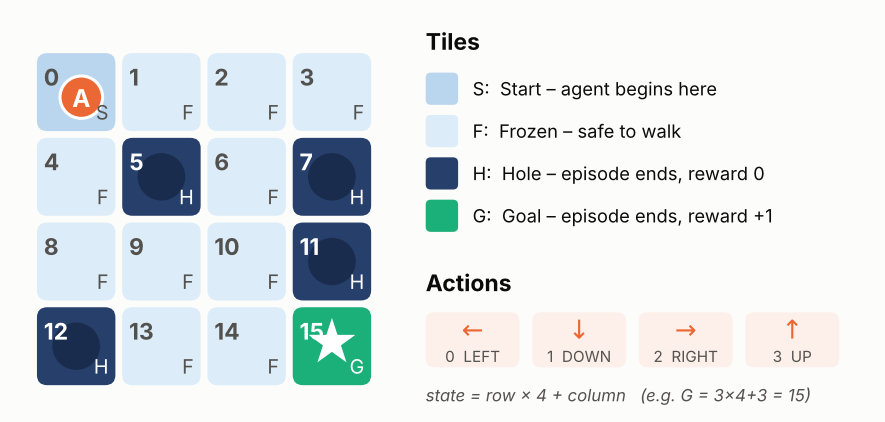

Useful options of `gym.make("FrozenLake-v1", ...)` (see the [documentation](https://gymnasium.farama.org/environments/toy_text/frozen_lake/)):

| Parameter | Values | Meaning |
|:--|:--|:--|
| `map_name` | `"4x4"` or `"8x8"` | size of the lake |
| `is_slippery` | `False` / `True` | `True`: the ice is slippery, the agent sometimes slides in a different direction (random!) |
| `render_mode` | `"rgb_array"` | `env.render()` returns an image (NumPy array) – needed for our videos |

<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 1 — create the environment**

Create the **4×4**, **non-slippery** FrozenLake environment with `render_mode="rgb_array"` and store it in the variable `env`.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

```python
env = gym.make("FrozenLake-v1", map_name=..., is_slippery=..., render_mode=...)
```

</details>

In [ ]:
env = ...  # YOUR CODE HERE

Let's look at the **observation space** (all possible states) and the **action space** (all possible actions):

In [ ]:
print("Observation space:", env.observation_space, " → e.g.", env.observation_space.sample())
print("Action space:     ", env.action_space, "  → e.g.", env.action_space.sample())

`Discrete(16)` means: the state is a single integer between 0 and 15 (`row * 4 + column`), and `Discrete(4)` means
there are 4 actions (0 = LEFT, 1 = DOWN, 2 = RIGHT, 3 = UP).

The two most important methods of every Gymnasium environment:

```python
state, info = env.reset()                                         # start a new episode
new_state, reward, terminated, truncated, info = env.step(action)  # perform one action
```

`terminated` is `True` when the episode ended *inside the game* (goal or hole), `truncated` when it was stopped from
outside (e.g. a step limit).

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎮 Widget: play FrozenLake yourself!**

Before the agent learns, **you** play. Use the buttons to move. Try to reach the goal — and also try to fall into a hole.
Watch the **state numbers** and **rewards** in the log. Notice how little feedback you get!

</div>

In [ ]:
#@title 🎮 Widget: play FrozenLake — run this cell
display(play_frozenlake(map_name="4x4", is_slippery=False))

## 2.2 Create the Q-table 🗄️

The Q-table needs one **row per state** and one **column per action**. Instead of typing 16 and 4 by hand, we read the
sizes from the environment, so that our code also works for other environments (Taxi has 500 × 6!):
`env.observation_space.n` and `env.action_space.n`.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 2 — initialise the Q-table**

1. Store the number of states in `state_space` and the number of actions in `action_space`.
2. Complete `initialize_q_table`: return a NumPy array of shape `(state_space, action_space)` filled with zeros.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

`np.zeros((rows, columns))` – note the double brackets: the shape is passed as a **tuple**.

</details>

In [ ]:
state_space = ...   # YOUR CODE HERE
action_space = ...  # YOUR CODE HERE
print("There are", state_space, "possible states and", action_space, "possible actions")


def initialize_q_table(state_space, action_space):
    Qtable = ...  # YOUR CODE HERE
    return Qtable


Qtable_frozenlake = initialize_q_table(state_space, action_space)
Qtable_frozenlake

<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✅ Check Task 2**

Run the cell below.

</div>

In [ ]:
check_initialize_q_table(initialize_q_table)

## 2.3 The greedy policy 🤖

The greedy policy **exploits** what we know: in state `state`, choose the action with the highest Q-value.
It is used (a) inside the ε-greedy policy and (b) as the **final policy** after training.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 3 — greedy policy**

Return the index of the largest value in the row of the Q-table that belongs to `state`.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

`Qtable[state]` is the row of state `state` (an array with one value per action).
`np.argmax(array)` returns the **index** of the largest entry.

</details>

In [ ]:
def greedy_policy(Qtable, state):
    # Exploitation: take the action with the highest Q-value in this state
    action = ...  # YOUR CODE HERE
    return action

In [ ]:
check_greedy_policy(greedy_policy)

## 2.4 The ε-greedy policy 🎲

During training we act with the ε-greedy policy (see the flowchart in 1.4).


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 4 — ε-greedy policy**

1. Draw a random number between 0 and 1.
2. If it is **larger than ε** → exploit: **reuse** your `greedy_policy`.
3. Otherwise → explore: return a **random action** (an integer between 0 and `n_actions − 1`).

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

- Random number in [0, 1]: `random.uniform(0, 1)`
- Number of actions: `Qtable.shape[1]` — a random action: `np.random.randint(Qtable.shape[1])`
  (or `env.action_space.sample()`)

</details>

In [ ]:
def epsilon_greedy_policy(Qtable, state, epsilon):
    random_num = ...  # YOUR CODE HERE: 1) random number in [0, 1]
    if random_num > epsilon:
        # 2) exploitation: take the best known action (reuse a function!)
        action = ...  # YOUR CODE HERE
    else:
        # 3) exploration: take a random action
        action = ...  # YOUR CODE HERE
    return action

In [ ]:
check_epsilon_greedy_policy(epsilon_greedy_policy)

## 2.5 Hyperparameters ⚙️

**Hyperparameters** are settings that are *not* learned but chosen by us before training. They can make the difference between
an agent that learns perfectly and one that learns nothing.

| Name | Value | Meaning |
|:--|:--|:--|
| `n_training_episodes` | 10 000 | how many episodes to train |
| `learning_rate` α | 0.7 | size of each update step |
| `gamma` γ | 0.95 | discount factor: how much future rewards count |
| `max_steps` | 99 | max. steps per episode (so that an episode always ends) |
| `max_epsilon` / `min_epsilon` | 1.0 / 0.05 | exploration rate at the start / at the end |
| `decay_rate` | 0.0005 | how fast ε decays (see the ε-widget above) |
| `n_eval_episodes` | 100 | episodes used to evaluate the trained agent |


<div style="background:#fdeaea; border-left:6px solid #e34948; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**⚠️ Exploration matters**

If ε decays **too fast** (too high `decay_rate`), the agent stops exploring before it has ever found the goal — it gets stuck
and never learns to solve the task.

</div>

In [ ]:
# Training parameters
n_training_episodes = 10000   # total training episodes
learning_rate = 0.7           # α
gamma = 0.95                  # γ  (discount rate)
max_steps = 99                # max steps per episode

# Exploration parameters
max_epsilon = 1.0             # exploration probability at start
min_epsilon = 0.05            # minimum exploration probability
decay_rate = 0.0005           # exponential decay rate for exploration probability

# Evaluation parameters
n_eval_episodes = 100         # number of test episodes
eval_seed = []                # FrozenLake: no special seeds needed

## 2.6 The training loop 🔁

Now the core of the algorithm. Most of the function is already written (including some code that records the training
history for nice plots, marked with 📊). Compare it with the pseudocode in 1.5.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 5 — complete the training loop**

Replace the four `...` in the inner loop:

- **(a)** choose an action with your **ε-greedy policy**
- **(b)** perform the action in the environment with `env.step(...)`
- **(c)** **update** `Qtable[state][action]` with the Q-learning update rule
- **(d)** move on: the new state becomes the current state

</div>

<details>
<summary><b>💡 Hint for (c)</b></summary>

(c) translated literally from the formula:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[\,r + \gamma \max_{a'} Q(s',a') - Q(s,a)\,]$$

`max_a' Q(s', a')` in NumPy is `np.max(Qtable[new_state])`.

</details>

In [ ]:
def train(env, Qtable, n_training_episodes, learning_rate, gamma, max_steps,
          min_epsilon, max_epsilon, decay_rate):
    history = {"rewards": [], "epsilons": [], "snapshots": {}}       # 📊 for plots

    for episode in tqdm(range(n_training_episodes)):
        # Reduce epsilon (we need less and less exploration)
        epsilon = min_epsilon + (max_epsilon - min_epsilon) * np.exp(-decay_rate * episode)
        # Reset the environment
        state, info = env.reset()
        episode_reward = 0

        for step in range(max_steps):
            # (a) choose action a with the epsilon-greedy policy
            action = ...  # YOUR CODE HERE

            # (b) take action a, observe new state s' and reward r
            new_state, reward, terminated, truncated, info = ...  # YOUR CODE HERE

            # (c) Q(s,a) := Q(s,a) + lr * [r + gamma * max_a' Q(s',a') - Q(s,a)]
            Qtable[state][action] = ...  # YOUR CODE HERE

            episode_reward += reward
            # stop if the episode is over (goal, hole, or step limit)
            if terminated or truncated:
                break

            # (d) the new state becomes the current state
            state = ...  # YOUR CODE HERE

        history["rewards"].append(episode_reward)                    # 📊
        history["epsilons"].append(epsilon)                          # 📊
        if take_snapshot(episode, n_training_episodes):              # 📊
            history["snapshots"][episode] = Qtable.copy()            # 📊
    return Qtable, history

<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✅ Check Task 5**

This trains a fresh agent for 1 500 episodes and compares some Q-values with the theoretical values.

</div>

In [ ]:
check_train(train)

## 2.7 Train the agent 🏃


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 6 — start the training**

Call your `train` function with the environment, the Q-table and the hyperparameters from 2.5. It returns the trained
Q-table and the training history.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

Use keyword arguments, that's easier to read:
```python
Qtable_frozenlake, history_frozenlake = train(env=env, Qtable=Qtable_frozenlake,
                                              n_training_episodes=n_training_episodes, ...)
```

</details>

In [ ]:
Qtable_frozenlake = initialize_q_table(state_space, action_space)   # start from scratch
Qtable_frozenlake, history_frozenlake = ...  # YOUR CODE HERE

### 📈 How did the training go?

The upper plot shows the reward per episode (averaged), the lower plot the exploration rate ε.

In [ ]:
plot_learning_curve(history_frozenlake, title="FrozenLake 4x4: training progress")

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q4)**

**Q4.** At the end the average training reward is clearly below 1.0, although the task is easy. Why?

</div>

### 👀 Look inside the agent's head

Left: the learned **greedy policy** on the map (arrow = best action, number = $\max_a Q(s,a)$). Right: the full **Q-table**.

In [ ]:
plot_q_table(Qtable_frozenlake, env, title="Trained Q-table")

<div style="background:#eaf2fb; border-left:6px solid #2a78d6; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎞️ Widget: watch the Q-table learn**

Press ▶ (or drag the slider) to see the Q-table at different moments of the training. **Where do the first non-zero values appear?**

</div>

In [ ]:
#@title 🎞️ Widget: watch the Q-table learn — run this cell
display(q_snapshot_widget(history_frozenlake, env))

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q5 & Q6)**

**Q5.** In which order do the states get non-zero values during training? Why?

**Q6.** Why is $\max_a Q(s,a)$ smaller the further a state is from the goal? Can you predict the value of the start state?

</div>

## 2.8 Evaluate the agent 📝

To measure how good the learned policy really is, we let the agent play `n_eval_episodes` episodes **without exploration**
(only the greedy policy) and average the rewards. This function is given — read it and make sure you understand it.

In [ ]:
def evaluate_agent(env, max_steps, n_eval_episodes, Q, seed):
    """
    Evaluate the greedy agent for n_eval_episodes episodes.
    Returns the mean and standard deviation of the episode rewards.
    :param seed: list of seeds (one per episode) – used for Taxi so everyone gets the same start positions
    """
    episode_rewards = []
    for episode in range(n_eval_episodes):
        if seed:
            state, info = env.reset(seed=seed[episode])
        else:
            state, info = env.reset()
        total_rewards_ep = 0

        for step in range(max_steps):
            action = greedy_policy(Q, state)          # no exploration during evaluation!
            new_state, reward, terminated, truncated, info = env.step(action)
            total_rewards_ep += reward
            if terminated or truncated:
                break
            state = new_state
        episode_rewards.append(total_rewards_ep)

    return np.mean(episode_rewards), np.std(episode_rewards)

<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 7 — evaluate**

Call `evaluate_agent` with the FrozenLake environment and your trained Q-table. You should get a mean reward of **1.00**.

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

The arguments are `(env, max_steps, n_eval_episodes, Q, seed)` – all of them are already defined in 2.5.

</details>

In [ ]:
mean_reward, std_reward = ...  # YOUR CODE HERE
print(f"Mean reward = {mean_reward:.2f} ± {std_reward:.2f}")

## 2.9 Watch your agent 🎬

Use the player below to step through an episode of your trained agent (or press ▶).

In [ ]:
#@title 🎬 Widget: watch your FrozenLake agent — run this cell
display(replay_widget(env, Qtable_frozenlake))

…or save the episode as a GIF (e.g. to share it):

In [ ]:
record_video(env, Qtable_frozenlake, "result_frozenlake.gif", fps=2)

<div style="background:#e6f6ef; border-left:6px solid #1baf7a; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🥳 Congratulations!**

You've just implemented and trained your first Reinforcement Learning agent from scratch.
But the non-slippery 4×4 lake is a very easy problem — let's try a harder one. 🔥

</div>

---
# Part 3 · Taxi 🚕

## 3.1 The environment

In [Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/) there are four marked locations **R**(ed), **G**(reen),
**Y**(ellow) and **B**(lue). An episode starts with the taxi at a random square and a passenger at one of the four locations.
The taxi has to drive to the passenger, **pick them up**, drive to the destination and **drop them off**.

How many states are there? The state must encode *everything* that matters:


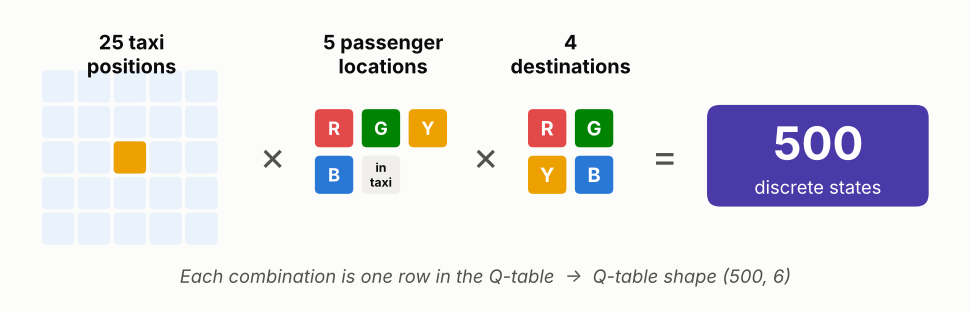

**Actions** (6):

| Action | Meaning |
|:--|:--|
| 0 | move south |
| 1 | move north |
| 2 | move east |
| 3 | move west |
| 4 | pick up passenger |
| 5 | drop off passenger |

**Rewards** — they do *not* belong to a specific action, they depend on the **situation** in which an action is taken:

| Situation | Reward |
|:--|:--|
| any normal step: driving (also into a wall), a *legal* pick-up | **−1** (⇒ hurry up!) |
| drop-off **with** the passenger in the taxi **at the destination** → episode ends | **+20** |
| drop-off with passenger at a *different* marked location (R/G/Y/B) → passenger gets out and waits there | **−1** |
| pick-up although the passenger is **not** at the taxi's position | **−10** |
| drop-off **without** passenger, or at a non-marked square | **−10** |

In [ ]:
env = gym.make(TAXI_ID, render_mode="rgb_array")   # TAXI_ID is "Taxi-v3" or "Taxi-v4", depending on your gymnasium version
state_space = env.observation_space.n
action_space = env.action_space.n
print("There are", state_space, "possible states and", action_space, "possible actions")

state, info = env.reset(seed=42)
display(IPyImage(frame_to_png(env.render()), width=330))

## 3.2 Hyperparameters ⚙️


<div style="background:#fdeaea; border-left:6px solid #e34948; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**⚠️ Do not modify `eval_seed`**

The seeds make sure that **everybody's agent is evaluated on the same 100 taxi start positions**, so results are comparable.

</div>

In [ ]:
# Training parameters
n_training_episodes = 25000   # total training episodes
learning_rate = 0.2           # α
gamma = 0.5                   # γ
max_steps = 99                # max steps per episode

# Exploration parameters
max_epsilon = 1.0
min_epsilon = 0.05
decay_rate = 0.005

# Evaluation parameters – DO NOT MODIFY eval_seed
n_eval_episodes = 100
eval_seed = [16, 54, 165, 177, 191, 191, 120, 80, 149, 178, 48, 38, 6, 125, 174, 73, 50, 172, 100, 148, 146, 6, 25,
             40, 68, 148, 49, 167, 9, 97, 164, 176, 61, 7, 54, 55, 161, 131, 184, 51, 170, 12, 120, 113, 95, 126, 51,
             98, 36, 135, 54, 82, 45, 95, 89, 59, 95, 124, 9, 113, 58, 85, 51, 134, 121, 169, 105, 21, 30, 11, 50, 65,
             12, 43, 82, 145, 152, 97, 106, 55, 31, 85, 38, 112, 102, 168, 123, 97, 21, 83, 158, 26, 80, 63, 5, 81, 32,
             11, 28, 148]

## 3.3 Train and evaluate 🏃

The great thing: **you don't need to write a single new learning function.** Your Q-learning code works for any environment
with discrete states and actions.


<div style="background:#fdf0ea; border-left:6px solid #eb6834; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**✏️ Task 8 — train and evaluate the taxi driver**

1. Create a new Q-table `Qtable_taxi` of the right size (use your function!).
2. Train it with `train(...)` and the Taxi hyperparameters → `Qtable_taxi, history_taxi`.
3. Evaluate it with `evaluate_agent(...)` – **don't forget `eval_seed`**. Can you reach a mean reward **≥ 7**?

</div>

<details>
<summary><b>💡 Hint (click to expand)</b></summary>

This is exactly what you did in Tasks 2, 6 and 7 — just with the new variables.

</details>

In [ ]:
Qtable_taxi = ...  # YOUR CODE HERE
print("Q-table shape:", Qtable_taxi.shape)

Qtable_taxi, history_taxi = ...  # YOUR CODE HERE

mean_reward, std_reward = ...  # YOUR CODE HERE
print(f"Mean reward = {mean_reward:.2f} ± {std_reward:.2f}")

In [ ]:
plot_learning_curve(history_taxi, title="Taxi: training progress")

### 🎬 Watch your taxi driver

In [ ]:
#@title 🎬 Widget: watch your taxi driver — run this cell
display(replay_widget(env, Qtable_taxi))

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🤔 Think about it (Q7)**

**Q7.** The mean reward is around 7.5 — but delivering a passenger gives +20. Where do the missing points go? Could any agent get much more?

</div>

## 3.4 🎛️ Hyperparameter lab

Time to experiment! The lab below trains **your** `train` function with the settings you choose and keeps a table of all runs.


<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🎯 Challenge**

1. Reach a mean reward **≥ 7 with only 2 000 training episodes** (instead of 25 000). Which hyperparameters matter most?
2. What happens with a very large `decay_rate` (e.g. 0.05)? With `gamma` = 0?

</div>

In [ ]:
#@title 🎛️ Hyperparameter lab — run this cell
display(hyperparameter_lab(train, evaluate_agent, eval_seed, default_env="Taxi"))

---
# Part 4 · Bonus challenges 🚀

Use the **hyperparameter lab** above (select a FrozenLake environment in the dropdown) or write your own cells.


<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🧊 B1 — slippery ice**

Select **FrozenLake 4x4 slippery**. Now the ice is slippery: the agent moves in the intended direction only with probability 1/3.
- Can your agent still reach a success rate of 100 %? Why (not)?
- Which `learning_rate` works better here — large or small? *(Think back to Q1.)*

</div>

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🗺️ B2 — the big lake**

Select **FrozenLake 8x8** (not slippery). With the default settings the agent usually learns **nothing** (mean reward 0).
- Look at the Q-table plot: why does the agent fail? *(Think back to Q3 and `np.argmax` of ties.)*
- Improve `greedy_policy` so that it picks **randomly among all best actions** when there is a tie. Re-run the cell of your new
  `greedy_policy`, then the lab again.

</div>

<div style="background:#fff5df; border-left:6px solid #eda100; border-radius:6px; padding:10px 18px; margin:10px 0; color:#1b1b1b;">

**🌍 B3 — the limits of tables**

A chess position, an image from a camera, the position of a robot arm … How big would the Q-table be? What could we do instead?

</div>

In [ ]:
# B2 – your improved greedy policy (optional)

---
# 🎉 Summary

- An RL agent learns from **rewards** by interacting with an environment (state → action → reward → new state).
- **Q-learning** stores the expected future reward of every state–action pair in a **Q-table** and improves it after every step with
  $Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma \max_{a'} Q(s',a') - Q(s,a)]$.
- Reward information spreads **backwards** from the goal through the table (bootstrapping).
- **ε-greedy** balances **exploration** and **exploitation**; ε decays over time.
- **Hyperparameters** (α, γ, ε-decay, number of episodes) strongly influence whether and how fast the agent learns.
- Tables only work for small, discrete problems → next step: **Deep Q-Learning**.